In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from tqdm.auto import tqdm

In [3]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.transforms import v2 as T

In [4]:
print("PyTorch:", torch.__version__)

PyTorch: 2.11.0+cu130


In [5]:
torch.random.manual_seed(42)
np.random.seed(42)

In [6]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

### __(1) Loading MNIST Digit Data__

In [7]:
transformation = T.Compose([
  T.ToImage(),
  T.ToDtype(torch.float32, scale=True), # Normalizes pixels to [0, 1]
  torch.flatten # Flattens output for use with NN
])

In [8]:

#MNIST: 28x28 grayscale digits (0-9)
train_dataset = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=transformation
)

test_dataset = datasets.MNIST(
    root="data",
    train=False,
    download=True,
    transform=transformation
)

In [9]:
train_sample = train_dataset[0]
test_sample = test_dataset[0]

In [10]:
print("Train:", (len(train_dataset), train_sample[0].shape[0]))
print("Test:", (len(test_dataset), test_sample[0].shape[0]))

Train: (60000, 784)
Test: (10000, 784)


In [11]:
train_dataset, val_dataset = random_split(
    train_dataset,
     [0.9, 0.1],
    generator=torch.Generator().manual_seed(42)
)

### __(2) Helper Functions for Visualization__

In [12]:
def show_reconstructions(original_flat: torch.Tensor, reconstructed_flat: torch.Tensor, n=10, title="Reconstruction"):
    """Show n originals and reconstructions side-by-side."""
    plt.figure(figsize=(2*n, 4))
    for i in range(n):
        # Original
        ax = plt.subplot(2, n, i + 1)
        plt.imshow(original_flat.cpu()[i].reshape(28, 28), cmap="gray")
        plt.axis("off")
        if i == 0:
            ax.set_title("Original")

        # Reconstructed
        ax = plt.subplot(2, n, i + 1 + n)
        plt.imshow(reconstructed_flat.cpu().detach()[i].reshape(28, 28), cmap="gray")
        plt.axis("off")
        if i == 0:
            ax.set_title("Reconstructed")

    plt.suptitle(title)
    plt.show()

In [13]:
def plot_history(train_losses: list[float], val_losses: list[float], title="Training Loss"):
    """Plot training (and validation) loss curves."""
    plt.figure(figsize=(6,4))
    plt.plot(train_losses, label="train_loss")
    plt.plot(val_losses, label="val_loss")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

In [14]:
def scatter_latent(z2d, labels, title="Latent Space (2D)"):
    """Scatter plot of 2D latent vectors colored by digit label."""
    plt.figure(figsize=(6,5))
    plt.scatter(z2d.cpu().detach()[:,0], z2d.cpu().detach()[:,1], c=labels, s=8, alpha=0.6)
    plt.colorbar()
    plt.title(title)
    plt.xlabel("z1")
    plt.ylabel("z2")
    plt.show()

### __(3) Simple Dense Autoencoder__

In [15]:
class Encoder(nn.Module):
  def __init__(self, latent_dim=32):
    super().__init__()
    self.linear1 = nn.Linear(784, 256)
    self.linear2 = nn.Linear(256, latent_dim)

  def forward(self, x):
    x = torch.relu(self.linear1(x))
    return self.linear2(x)

In [16]:
class Decoder(nn.Module):
  def __init__(self, latent_dim=32):
    super().__init__()
    self.linear1 = nn.Linear(latent_dim, 256)
    self.linear2 = nn.Linear(256, 784)

  def forward(self, z):
    z = torch.relu(self.linear1(z))
    return torch.sigmoid(self.linear2(z))

In [17]:
class AutoEncoder(nn.Module):
  def __init__(self, latent_dim=32):
    super().__init__()
    self.encoder = Encoder(latent_dim)
    self.decoder = Decoder(latent_dim)

  def forward(self, x):
    return self.decoder(self.encoder(x))

In [18]:
def train_autoencoder(ae: AutoEncoder, batch_size=256, epochs=10, leave=True):
  train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
  val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

  optimizer = optim.Adam(ae.parameters(), lr=0.001)
  loss_func = nn.BCELoss()

  train_losses = []
  val_losses = []

  for epoch in range(1, epochs + 1):
    train_pbar = tqdm(train_loader, desc=f'Epoch {epoch}/{epochs} - Train', leave=leave)
    train_loss = 0
    for x, _ in train_pbar:
      x = x.to(device)
      optimizer.zero_grad()
      x_recon = ae(x)
      loss = loss_func(x_recon, x)
      loss.backward()
      optimizer.step()
      train_loss += loss
      train_pbar.set_postfix({'train_loss': train_loss.item()})

    train_loss /= len(train_loader)

    val_pbar = tqdm(val_loader, desc=f'Epoch {epoch}/{epochs} - Val', leave=leave)
    val_loss = 0
    with torch.no_grad():
      for x, _ in val_pbar:
        x = x.to(device)
        x_recon = ae(x)
        loss = loss_func(x_recon, x)
        val_loss += loss
        val_pbar.set_postfix({'val_loss': val_loss.item()})

    val_loss /= len(val_loader)

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

  return train_losses, val_losses

### __(4) Training above AE + Reconstruction viz__

In [19]:
LATENT_DIM = 32
EPOCHS_AE = 8
BATCH_SIZE = 2048

In [20]:
ae = AutoEncoder(LATENT_DIM).to(device)

In [21]:
print(ae)

AutoEncoder(
  (encoder): Encoder(
    (linear1): Linear(in_features=784, out_features=256, bias=True)
    (linear2): Linear(in_features=256, out_features=32, bias=True)
  )
  (decoder): Decoder(
    (linear1): Linear(in_features=32, out_features=256, bias=True)
    (linear2): Linear(in_features=256, out_features=784, bias=True)
  )
)


In [22]:
print('Number of parameters:', sum([layer.flatten().shape[0] for layer in ae.parameters()]))

Number of parameters: 419120


In [23]:
train_losses, val_losses = train_autoencoder(ae, batch_size=BATCH_SIZE, epochs=EPOCHS_AE)

Epoch 1/8 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 1/8 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 2/8 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 2/8 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 3/8 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

...

Epoch 6/8 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 7/8 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 7/8 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 8/8 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 8/8 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

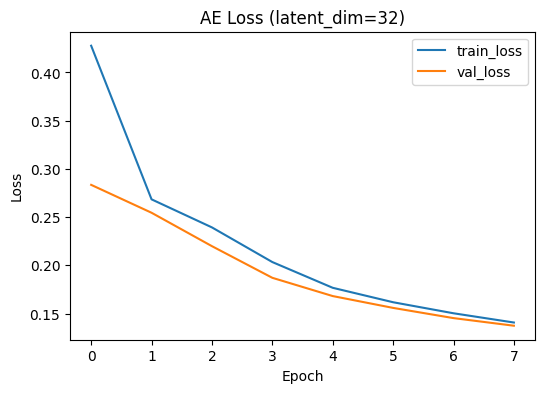

In [24]:
plot_history(train_losses, val_losses, title=f"AE Loss (latent_dim={LATENT_DIM})")

For training AE:
- I/P = original images
- Target = original images (same)
- Reconstruction task

In [25]:
t = [test_dataset[i] for i in range(2000)]
y_sample = [tup[1] for tup in t]
x_sample = torch.cat([tup[0].unsqueeze(0) for tup in t]).to(device)

In [26]:
x_recon = ae(x_sample)

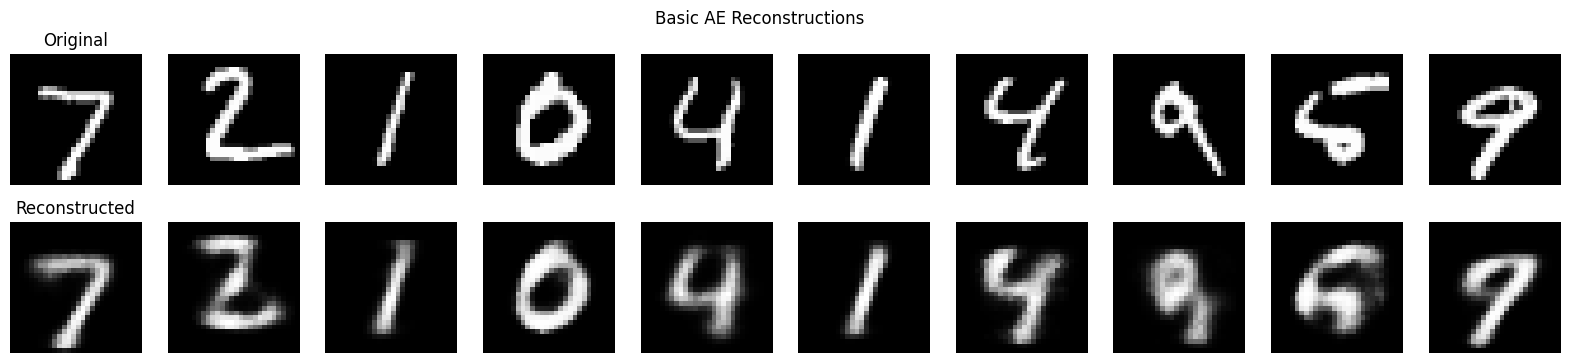

In [27]:
show_reconstructions(x_sample, x_recon, n=10, title="Basic AE Reconstructions")

### __(5) Comparison of different Latent Dim__

- Smaller latent_dim → more compression → harder reconstruction → model must keep only “essential” features.

In [28]:
latent_dims = [2, 32, 128]
recons = {}

In [29]:
for ld in latent_dims:
    ae = AutoEncoder(latent_dim=ld).to(device)
    train_autoencoder(ae, batch_size=BATCH_SIZE, epochs=5, leave=False)
    recons[ld] = ae(x_sample)

Epoch 1/5 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 1/5 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 2/5 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 2/5 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 3/5 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

...

Epoch 3/5 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 4/5 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 4/5 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 5/5 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 5/5 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

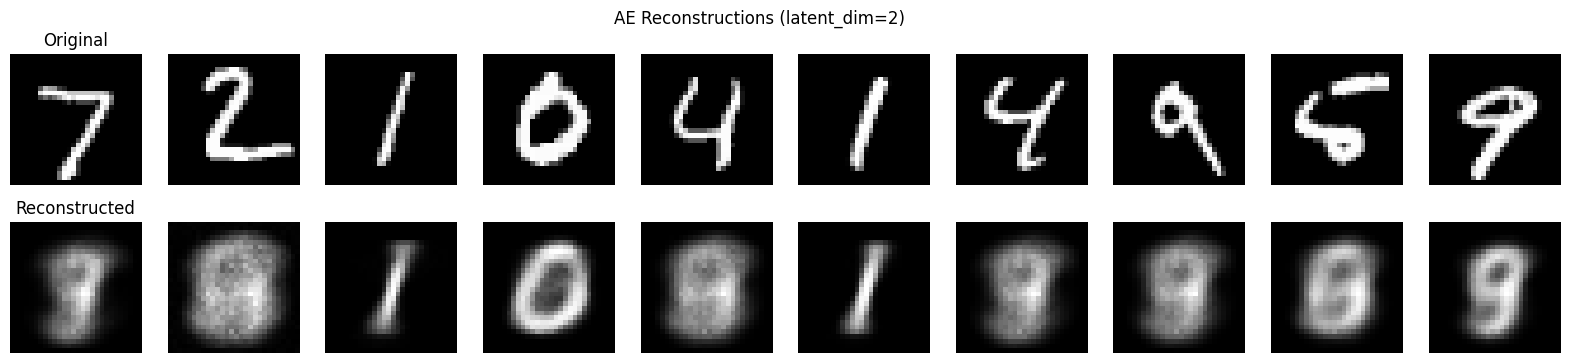

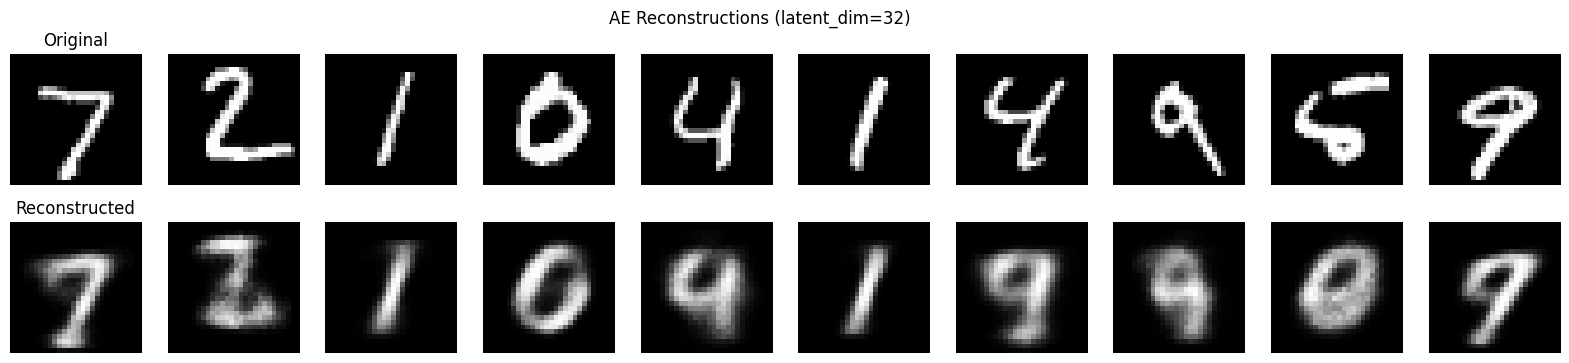

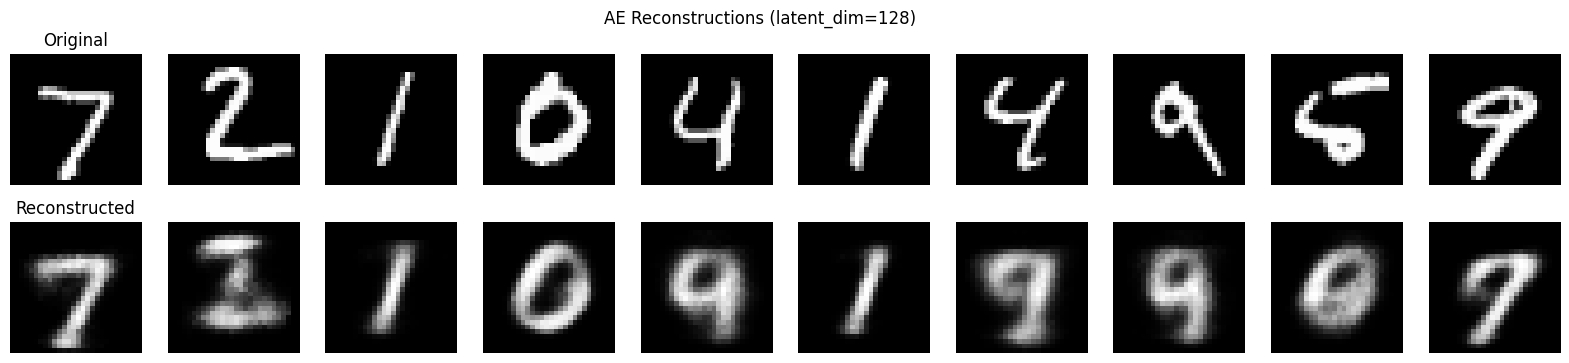

In [30]:
for ld in latent_dims:
    show_reconstructions(x_sample, recons[ld], n=10, title=f"AE Reconstructions (latent_dim={ld})")

### __(6) Latent Space Visualization__ `(latent_dim=2)`

In [31]:
ae2 = AutoEncoder(latent_dim=2).to(device)

In [32]:
_ = train_autoencoder(ae2, epochs=8)

Epoch 1/8 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 1/8 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 2/8 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 2/8 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 3/8 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

...

Epoch 6/8 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 7/8 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 7/8 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 8/8 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 8/8 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

In [33]:
z_test_ae2 = ae2.encoder(x_sample)

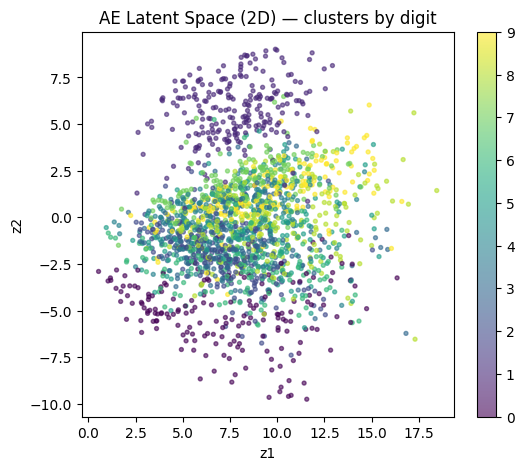

In [34]:
scatter_latent(z_test_ae2, y_sample, title="AE Latent Space (2D) — clusters by digit")

AE learns: **`Input image → reconstruct same image`** which is a deterministic mapping of x → z → x̂ where,

- z = f(x)
- x̂ = g(z)


### __(7) Why Vanilla AE is Not Generative (Random z Sampling)__

> If latent space is not structured, random sampling usually fails.

In [35]:
# Sample random points (uniform) and decode
z_random = torch.Tensor(size=(20, 2)).uniform_(-5, 5).to(device)
x_gen = ae2.decoder(z_random)

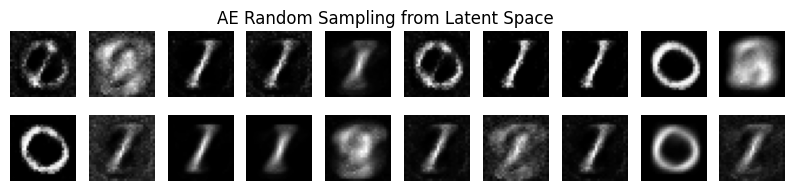

In [36]:
plt.figure(figsize=(10, 2))
for i in range(20):
    ax = plt.subplot(2, 10, i+1)
    plt.imshow(x_gen.cpu().detach()[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.suptitle("AE Random Sampling from Latent Space")
plt.show()

- AE __did not learn a full latent distribution__

- It only learned encodings for __actual training data__

- It does not know what “valid latent space” looks like

### __(8) Variational Autoencoder (VAE)__

- In VAE,

  - The encoder does not output a fixed vector z.

  - It outputs a distribution (mean and variance) conditioned on that input image i.e. for each input image x, the encoder o/p:
    - μ(x) → center of latent Gaussian (vector of dim = latent_dim)
    - σ(x) → spread of latent Gaussian (vector of dim = latent_dim)
    
  - This means that each image maps to a Gaussian cloud in latent space now if we sample a random point from z ∼ N(μ,σ^2), the gradient cannot properly flow through that sampling step.

#### __Reparameterization Trick__

1. __Encoder Outputs Distribution Parameters:__ For each input image x, the encoder outputs μ(x) and σ(x).

2. __Introduce Random Noise:__ We sample a random variable ϵ from a standard normal distribution N(0,1). This is just standard Gaussian noise.

3. __Reparameterize the Latent Variable:__ We sample a standard random number ε,
then shift it by μ and scale it by σ by the formula: `z = μ + σ·ε`

4. __Enable Differentiability:__ This gives us a sample from: `𝑁(𝜇, 𝜎^2)` which is now diffrentiable.

5. Reparameterized z is fed into the decoder to reconstruct the input or generate outputs.



In [37]:
class VEncoder(nn.Module):
  def __init__(self, latent_dim=32):
    super().__init__()
    self.linear1 = nn.Linear(784, 256)
    self.linear_mu = nn.Linear(256, latent_dim)
    self.linear_logvar = nn.Linear(256, latent_dim)

  def forward(self, x):
    x = torch.relu(self.linear1(x))
    mu = self.linear_mu(x)
    logvar = self.linear_logvar(x)
    return mu, logvar

In [38]:
class VDecoder(nn.Module):
  def __init__(self, latent_dim=32):
    super().__init__()
    self.linear1 = nn.Linear(latent_dim, 256)
    self.linear2 = nn.Linear(256, 784)

  def forward(self, z):
    z = torch.relu(self.linear1(z))
    return torch.sigmoid(self.linear2(z))

In [39]:
class VAE(nn.Module):
  def __init__(self, latent_dim=32):
    super().__init__()
    self.encoder = VEncoder(latent_dim)
    self.decoder = VDecoder(latent_dim)

  def reparameterize(self, mu, logvar):
    std = torch.exp(0.5 * logvar)
    eps = torch.randn_like(std)
    return mu + eps * std

  def forward(self, x):
    mu, logvar = self.encoder(x)
    z = self.reparameterize(mu, logvar)
    return self.decoder(z), mu, logvar

### __KL Divergence:__

For each input image **x**, the encoder predicts a latent Gaussian distribution:

$$
q(z|x) = {N}(\mu(x), \sigma(x)^2)
$$

We also define a prior distribution over the latent space:

$$
p(z) = {N}(0, 1)
$$

KL divergence measures:

$$
KL\big(q(z|x) \;||\; p(z)\big)
$$


In [40]:
def train_vae(vae: VAE, batch_size=256, epochs=10, leave=True):
  train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
  val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

  optimizer = optim.Adam(vae.parameters(), lr=0.001)
  bce = nn.BCELoss(reduction='sum')
  kld = lambda mu, logvar: -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

  training_bce_losses = []
  training_kld_losses = []
  training_losses = []

  val_bce_losses = []
  val_kld_losses = []
  val_losses = []

  for epoch in range(1, epochs + 1):
    train_pbar = tqdm(train_loader, desc=f'Epoch {epoch}/{epochs} - Train', leave=leave)

    train_bce_loss = 0
    train_kld_loss = 0
    train_loss = 0

    for x, _ in train_pbar:
      x = x.to(device)
      optimizer.zero_grad()
      x_recon, mu, logvar = vae(x)

      bce_loss = bce(x_recon, x)
      kld_loss = kld(mu, logvar)
      loss = bce_loss + kld_loss

      loss.backward()
      optimizer.step()

      train_bce_loss += bce_loss.item()
      train_kld_loss += kld_loss.item()
      train_loss += loss.item()

      train_pbar.set_postfix({
          'train_bce_loss': train_bce_loss,
          'train_kld_loss': train_kld_loss,
          'train_loss': train_loss
      })

    train_bce_loss /= len(train_loader)
    train_kld_loss /= len(train_loader)
    train_loss /= len(train_loader)

    with torch.no_grad():
      val_pbar = tqdm(val_loader, desc=f'Epoch {epoch}/{epochs} - Val', leave=leave)

      val_bce_loss = 0
      val_kld_loss = 0
      val_loss = 0

      for x, _ in val_pbar:
        x = x.to(device)
        x_recon, mu, logvar = vae(x)

        bce_loss = bce(x_recon, x)
        kld_loss = kld(mu, logvar)
        loss = bce_loss + kld_loss

        val_bce_loss += bce_loss.item()
        val_kld_loss += kld_loss.item()
        val_loss += loss.item()
        val_pbar.set_postfix({
            'val_bce_loss': val_bce_loss,
            'val_kld_loss': val_kld_loss,
            'val_loss': val_loss
        })

      val_bce_loss /= len(val_loader)
      val_kld_loss /= len(val_loader)
      val_loss /= len(val_loader)

    training_bce_losses.append(train_bce_loss)
    training_kld_losses.append(train_kld_loss)
    training_losses.append(train_loss)

    val_bce_losses.append(val_bce_loss)
    val_kld_losses.append(val_kld_loss)
    val_losses.append(val_loss)

  return {
      'train': {
          'bce': training_bce_losses,
          'kld': training_kld_losses,
          'total': training_losses
      },
      'val': {
          'bce': val_bce_losses,
          'kld': val_kld_losses,
          'total': val_losses
      }
  }

### __(9) Train VAE + Plot Losses__

In [41]:
LATENT_DIM_VAE = 2
EPOCHS_VAE = 10

In [42]:
vae = VAE(latent_dim=LATENT_DIM).to(device)

In [43]:
print(vae)

VAE(
  (encoder): VEncoder(
    (linear1): Linear(in_features=784, out_features=256, bias=True)
    (linear_mu): Linear(in_features=256, out_features=32, bias=True)
    (linear_logvar): Linear(in_features=256, out_features=32, bias=True)
  )
  (decoder): VDecoder(
    (linear1): Linear(in_features=32, out_features=256, bias=True)
    (linear2): Linear(in_features=256, out_features=784, bias=True)
  )
)


In [44]:
print('Number of parameters:', sum([layer.flatten().shape[0] for layer in vae.parameters()]))

Number of parameters: 427344


In [45]:
vae_losses = train_vae(vae, batch_size=BATCH_SIZE, epochs=EPOCHS_VAE, leave=False)

Epoch 1/10 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 1/10 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 2/10 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 2/10 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 3/10 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

...

Epoch 8/10 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 9/10 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 9/10 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

Epoch 10/10 - Train:   0%|          | 0/27 [00:00<?, ?it/s]

Epoch 10/10 - Val:   0%|          | 0/3 [00:00<?, ?it/s]

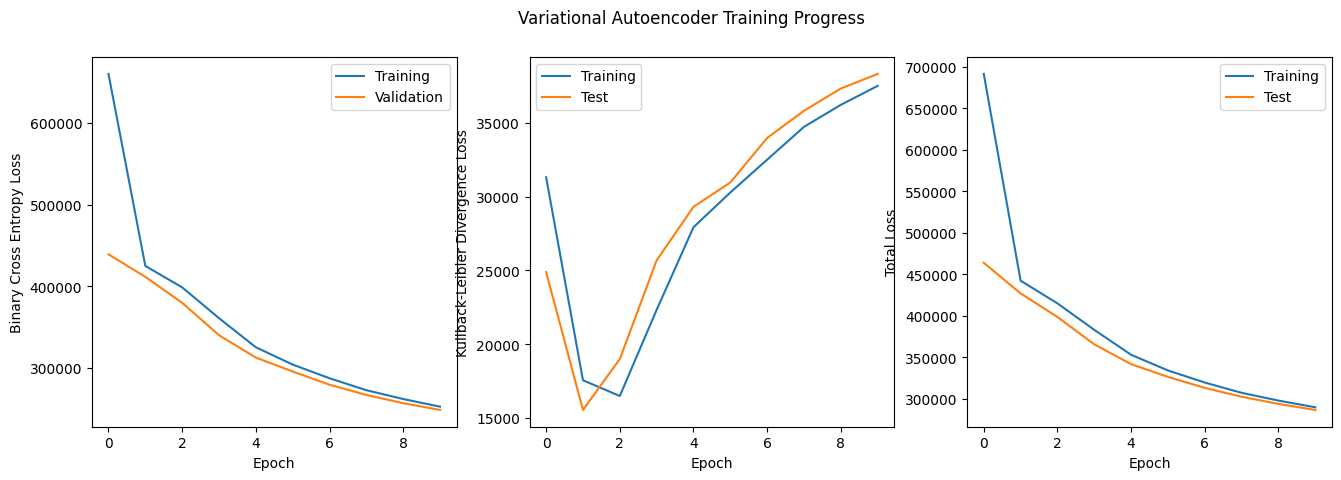

In [46]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(6.4 * 2.5, 4.8))

ax1.plot(vae_losses['train']['bce'], label='Training')
ax1.plot(vae_losses['val']['bce'], label='Validation')
ax1.legend()
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Binary Cross Entropy Loss')

ax2.plot(vae_losses['train']['kld'], label='Training')
ax2.plot(vae_losses['val']['kld'], label='Test'),
ax2.legend()
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Kullback-Leibler Divergence Loss')

ax3.plot(vae_losses['train']['total'], label='Training')
ax3.plot(vae_losses['val']['total'], label='Test'),
ax3.legend()
ax3.set_xlabel('Epoch')
ax3.set_ylabel('Total Loss')

fig.suptitle('Variational Autoencoder Training Progress')
plt.show()

### __(10) Compare Reconstructions (AE vs VAE)__

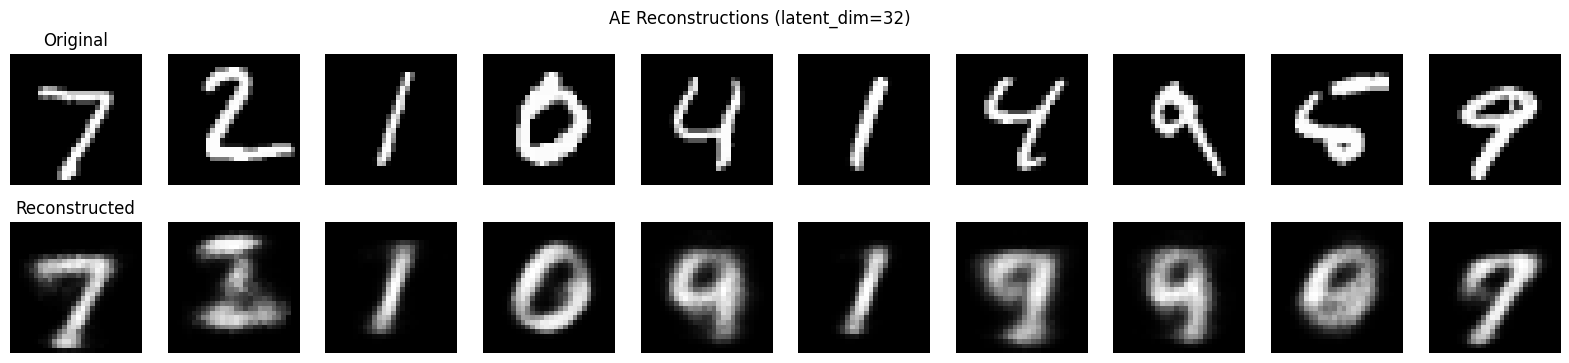

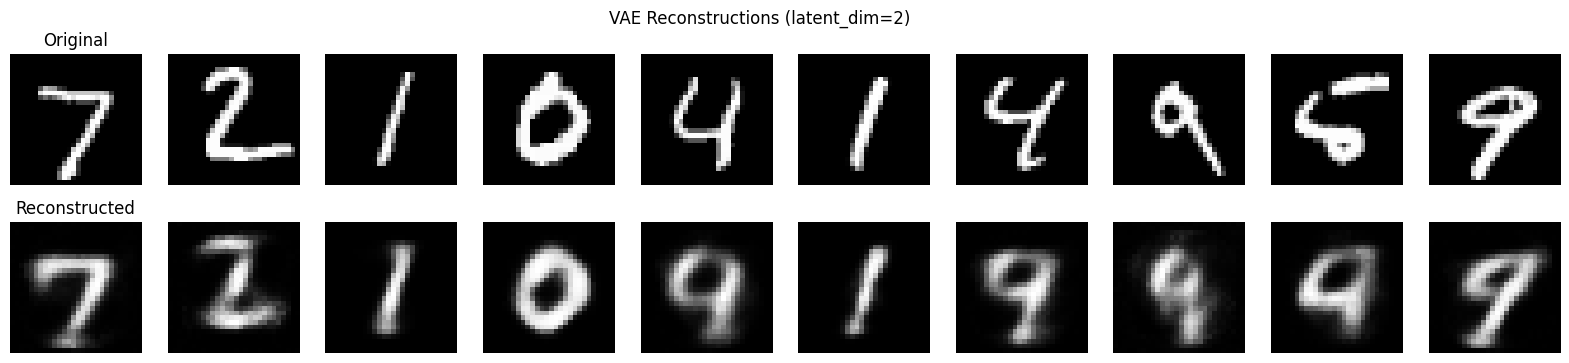

In [47]:
# Use the previously trained AE with latent_dim=32 (ae)
x_ae_recon = ae(x_sample[:10])

# VAE reconstruction
x_vae_recon, mu, logvar = vae(x_sample[:10])

# Show comparisons
show_reconstructions(x_sample, x_ae_recon, n=10, title="AE Reconstructions (latent_dim=32)")
show_reconstructions(x_sample, x_vae_recon, n=10, title="VAE Reconstructions (latent_dim=2)")

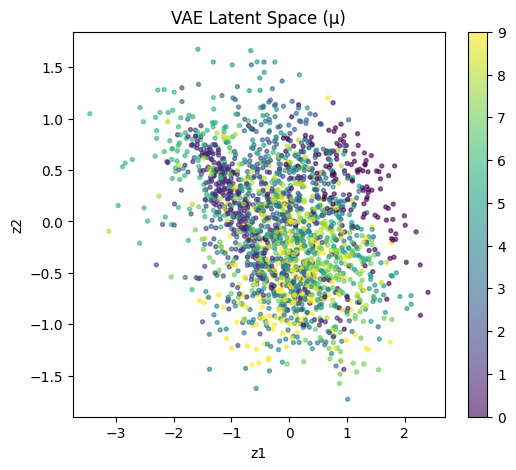

In [48]:
z_mean_test, _ = vae.encoder(x_sample)
scatter_latent(z_mean_test, y_sample, title="VAE Latent Space (μ)")

In [49]:
# Interpolate between two test images in latent space.
idx_a, idx_b = 0, 1

x_a = x_sample[0].unsqueeze(0)
x_b = x_sample[1].unsqueeze(0)

# Encode to means (μ)
mu_a, _ = vae.encoder(x_a)
mu_b, _ = vae.encoder(x_b)

In [50]:
steps = 12
alphas = torch.linspace(0, 1, steps, dtype=torch.float32).reshape(-1, 1).to(device)
z_interp = (1 - alphas) * mu_a + alphas * mu_b

x_interp = vae.decoder(z_interp)

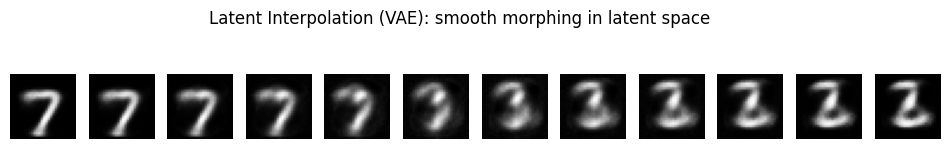

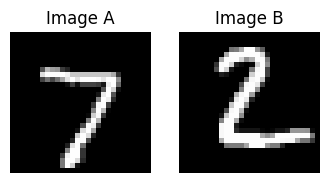

In [51]:
plt.figure(figsize=(12, 2))
for i in range(steps):
    ax = plt.subplot(1, steps, i+1)
    plt.imshow(x_interp.cpu().detach()[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.suptitle("Latent Interpolation (VAE): smooth morphing in latent space")
plt.show()

# Also show endpoints
plt.figure(figsize=(4,2))

plt.subplot(1,2,1)
plt.imshow(x_a.cpu().detach().reshape(28,28), cmap="gray")
plt.axis("off")
plt.title("Image A")

plt.subplot(1,2,2)
plt.imshow(x_b.cpu().detach().reshape(28,28), cmap="gray")
plt.axis("off")
plt.title("Image B")

plt.show()

We encode two images into latent space, then walk in a straight line between their latent points.
If the model learned a smooth representation, the decoded images should gradually morph from one digit to the other.